<a href="https://colab.research.google.com/github/duakhurram2212/smart_retail/blob/main/notebooks/modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 0. Setup


In [1]:
# Clone the project repo (skipped if already present), move into it and install dependencies
!git clone -q https://github.com/duakhurram2212/smart_retail.git 2>/dev/null || true
%cd /content/smart_retail
!pip install -q -r requirements.txt
!pip install -q xgboost shap

/content/smart_retail


## 1. Data Loading and Target Definition


In [ ]:
import numpy as np, pandas as pd

df = pd.read_parquet("data/processed/features_engineered.parquet")
df = df[(df["reliable_period"] == 1) & (df["is_store_open"] == 1)].copy()
df["y"] = np.log1p(df["sales"])
print(df.shape)

(1330527, 63)


## 2. Time-Based Train / Validation Split and Feature Selection


In [ ]:
last = df["date"].max()
val_start = last - pd.Timedelta(days=27)
es_start  = val_start - pd.Timedelta(days=14)

train = df[df["date"] < val_start].copy()
valid = df[df["date"] >= val_start].copy()
valid["week"] = ((valid["date"] - val_start).dt.days // 7) + 1

drop = ["id","date","sales","y","week","city","state","store_type","family",
        "is_store_open","reliable_period","promo_recorded"]
features = [c for c in df.columns if c not in drop]
features = [c for c in features if train[c].nunique() > 1]
print(len(features), "features | train", train.shape, "| valid", valid.shape)

52 features | train (1280631, 63) | valid (49896, 64)


## 3. Preprocessing for Gradient Descent Regression


In [ ]:
gd_train = train.dropna(subset=features).copy()
gd_valid = valid.dropna(subset=features).copy()

cat_cols = ["store_nbr","family_code","store_type_code","store_cluster","day_of_week","month"]
skip     = ["city_code","state_code","quarter","onpromotion"]
log_cols = ["sales_lag_7d","sales_lag_14d","sales_lag_21d","sales_lag_28d",
            "sales_same_dow_mean_4w","rolling_mean_7d","rolling_std_7d",
            "rolling_mean_14d","rolling_std_14d","rolling_mean_28d","rolling_std_28d",
            "onpromotion_lag_7d","transactions_lag_7d","transactions_roll_7d"]
num_cols = [c for c in features if c not in cat_cols + skip]

cap = gd_train["promo_intensity_vs_28d"].quantile(0.99)

def prep(d):
    X = d[num_cols + cat_cols].copy()
    for c in log_cols:
        if c in X: X[c] = np.log1p(X[c].clip(lower=0))
    X["promo_intensity_vs_28d"] = np.log1p(X["promo_intensity_vs_28d"].clip(0, cap))
    return X

Xtr, Xva = prep(gd_train), prep(gd_valid)
n_tr = len(Xtr)
allX = pd.get_dummies(pd.concat([Xtr, Xva]), columns=cat_cols, drop_first=True, dtype=np.float32)
allX = allX.astype(np.float32)
Xtr_oh, Xva_oh = allX.iloc[:n_tr], allX.iloc[n_tr:]

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(Xtr_oh)
Xtr_s = scaler.transform(Xtr_oh).astype(np.float32)
Xva_s = scaler.transform(Xva_oh).astype(np.float32)
ytr, yva = gd_train["y"].values.astype(np.float32), gd_valid["y"].values.astype(np.float32)
gd_features = list(allX.columns)
print(Xtr_s.shape, Xva_s.shape)

(1266639, 164) (49896, 164)


## 4. Gradient Descent Regression (from scratch) and Evaluation Metrics


In [ ]:
class GDRegression:
    def __init__(self, lr=0.05, epochs=500, l1=0.0, l2=0.0):
        self.lr, self.epochs, self.l1, self.l2 = lr, epochs, l1, l2
    def fit(self, X, y):
        n, d = X.shape
        self.w = np.zeros(d, dtype=np.float32); self.b = np.float32(0)
        self.loss_history = []
        for _ in range(self.epochs):
            err = X @ self.w + self.b - y
            dw = X.T @ err / n + 2*self.l2*self.w + self.l1*np.sign(self.w)
            self.w -= self.lr * dw
            self.b -= self.lr * err.mean()
            self.loss_history.append(float((err**2).mean()/2
                + self.l2*(self.w**2).sum() + self.l1*np.abs(self.w).sum()))
        return self
    def predict(self, X):
        return X @ self.w + self.b

def metrics(y_log, p_log, sales):
    p_log = np.clip(p_log, 0, None)
    p = np.expm1(p_log)
    nz = sales > 0
    return {"RMSLE": np.sqrt(np.mean((p_log - y_log)**2)),
            "RMSE":  np.sqrt(np.mean((p - sales)**2)),
            "MAPE":  np.mean(np.abs(p[nz]-sales[nz])/sales[nz])*100,   # sirf sales>0 rows
            "R2":    1 - np.sum((sales-p)**2)/np.sum((sales-sales.mean())**2)}

def weekly_report(vdf, p_log):
    rows = []
    for w in sorted(vdf["week"].unique()):
        m = (vdf["week"] == w).values
        rows.append(metrics(vdf["y"].values[m], p_log[m], vdf["sales"].values[m]))
    return pd.DataFrame(rows, index=[f"W{w}" for w in sorted(vdf["week"].unique())])

## 5. Training GD Regression: No Regularization vs L2 vs L1



GD (no reg) 
     RMSLE     RMSE    MAPE     R2
W1  0.412  227.068  33.119  0.967
W2  0.455  376.042  33.566  0.924
W3  0.483  295.426  34.990  0.949
W4  0.455  258.206  38.402  0.949 

GD + L2 
     RMSLE     RMSE    MAPE     R2
W1  0.412  226.505  33.130  0.967
W2  0.455  375.517  33.565  0.925
W3  0.483  295.110  34.996  0.949
W4  0.455  258.157  38.423  0.949 

GD + L1 
     RMSLE     RMSE    MAPE     R2
W1  0.412  226.458  33.120  0.967
W2  0.455  375.387  33.547  0.925
W3  0.482  294.517  35.009  0.949
W4  0.455  258.200  38.437  0.949 



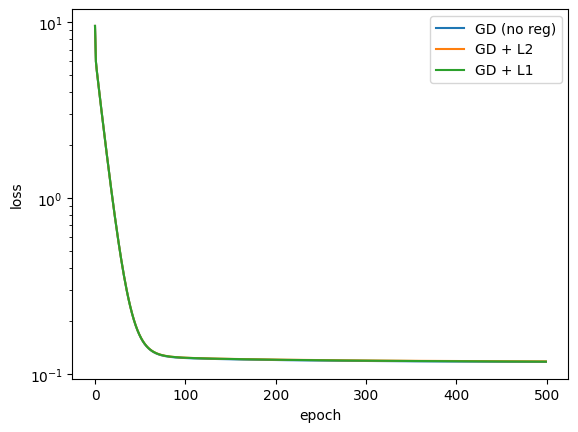

In [ ]:
import matplotlib.pyplot as plt
configs = {"GD (no reg)": dict(), "GD + L2": dict(l2=1e-3), "GD + L1": dict(l1=1e-4)}
gd_models, results = {}, {}
for name, kw in configs.items():
    m = GDRegression(lr=0.05, epochs=500, **kw).fit(Xtr_s, ytr)
    gd_models[name] = m
    rep = weekly_report(gd_valid, m.predict(Xva_s))
    results[name] = rep.mean()
    plt.plot(m.loss_history, label=name)
    print(name, "\n", rep.round(3), "\n")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.show()

## 6. Validation Against scikit-learn (LinearRegression, Ridge, Lasso)


In [ ]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
idx = np.random.RandomState(0).choice(len(Xtr_s), 200_000, replace=False)
Xs, ys = Xtr_s[idx], ytr[idx]; n = len(Xs)

for name, kw, sk in [("no reg", {}, LinearRegression()),
                     ("L2", dict(l2=1e-3), Ridge(alpha=2*n*1e-3)),
                     ("L1", dict(l1=1e-4), Lasso(alpha=1e-4, max_iter=2000))]:
    mine = GDRegression(lr=0.05, epochs=1500, **kw).fit(Xs, ys)
    sk.fit(Xs, ys)
    d = np.abs(mine.predict(Xva_s) - sk.predict(Xva_s)).mean()
    print(f"{name}: mean |pred difference| = {d:.4f}")

no reg: mean |pred difference| = 0.0095
L2: mean |pred difference| = 0.0091
L1: mean |pred difference| = 0.0175


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.285e+02, tolerance: 1.316e+02
  model = cd_fast.enet_coordinate_descent(


## 7. Regularization Strength (λ) Sweep and Weight Sparsity


In [ ]:
sweep = []
for kind, vals in [("l2", [1e-3, 1e-2, 1e-1, 1]), ("l1", [1e-4, 1e-3, 1e-2, 5e-2])]:
    for lam in vals:
        m = GDRegression(lr=0.05, epochs=300, **{kind: lam}).fit(Xtr_s, ytr)
        rep = weekly_report(gd_valid, m.predict(Xva_s)).mean()
        sweep.append({"type": kind, "lambda": lam,
                      "RMSLE": rep["RMSLE"], "RMSE": rep["RMSE"],
                      "near_zero_weights": int((np.abs(m.w) < 1e-3).sum()),
                      "total_weights": len(m.w)})
sweep_df = pd.DataFrame(sweep).round(4)
print(sweep_df)

  type  lambda   RMSLE      RMSE  near_zero_weights  total_weights
0   l2  0.0010  0.4521  287.8753                 13            164
1   l2  0.0100  0.4521  286.4200                 13            164
2   l2  0.1000  0.4575  285.9336                 13            164
3   l2  1.0000  0.5542  547.3682                 16            164
4   l1  0.0001  0.4518  287.5770                 16            164
5   l1  0.0010  0.4502  284.0857                 45            164
6   l1  0.0100  0.4465  262.7833                132            164
7   l1  0.0500  0.4500  288.1152                 57            164


## 8. XGBoost: Randomized Hyperparameter Search with Early Stopping


In [ ]:
import xgboost as xgb
from sklearn.model_selection import ParameterSampler

fit_df = train[train["date"] < es_start]
es_df  = train[train["date"] >= es_start]
Xf, yf = fit_df[features], fit_df["y"]
Xe, ye = es_df[features],  es_df["y"]

space = dict(max_depth=[4,6,8,10], learning_rate=[0.03,0.05,0.1],
             subsample=[0.7,0.8,1.0], colsample_bytree=[0.6,0.8,1.0],
             min_child_weight=[1,5,20])
best = (9, None, None)
for p in ParameterSampler(space, n_iter=10, random_state=42):
    m = xgb.XGBRegressor(n_estimators=1000, early_stopping_rounds=50,
                         tree_method="hist", random_state=42, n_jobs=-1, **p)
    m.fit(Xf, yf, eval_set=[(Xe, ye)], verbose=False)
    score = m.best_score
    print(p, round(score, 4), m.best_iteration)
    if score < best[0]: best = (score, p, m.best_iteration)

final = xgb.XGBRegressor(n_estimators=best[2]+1, tree_method="hist",random_state=42, n_jobs=-1, **best[1])
final.fit(train[features], train["y"])

{'subsample': 0.7, 'min_child_weight': 20, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 0.8} 0.3738 562
{'subsample': 0.7, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.8} 0.3832 419
{'subsample': 1.0, 'min_child_weight': 1, 'max_depth': 10, 'learning_rate': 0.03, 'colsample_bytree': 0.8} 0.3729 501
{'subsample': 0.7, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.6} 0.3743 999
{'subsample': 0.7, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 0.8} 0.3788 606
{'subsample': 0.7, 'min_child_weight': 1, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 0.8} 0.3735 540
{'subsample': 0.7, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 1.0} 0.3812 998
{'subsample': 0.8, 'min_child_weight': 20, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 0.8} 0.3734 618
{'subsample': 1.0, 'min_child_weight': 5, 'max_depth': 6, 'lear

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.03, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=10,
             max_leaves=None, min_child_weight=1, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=502,
             n_jobs=-1, num_parallel_tree=None, ...)

## 9. Final Model Comparison and Saving Predictions


In [ ]:
import os
os.makedirs("outputs/predictions", exist_ok=True)

rep_x = weekly_report(valid.loc[gd_valid.index], final.predict(valid.loc[gd_valid.index, features]))
results["XGBoost"] = rep_x.mean()

gd_best = GDRegression(lr=0.05, epochs=500, l1=0.01).fit(Xtr_s, ytr)
gd_models["GD + L1 (best, λ=0.01)"] = gd_best
results["GD + L1 (best, λ=0.01)"] = weekly_report(gd_valid, gd_best.predict(Xva_s)).mean()

table = pd.DataFrame(results).T.round(4)
print(table)
table.to_csv("outputs/metrics_table.csv")

final_out = gd_valid[["date","store_nbr","family"]].copy()
final_out["pred_regression"] = np.expm1(np.clip(gd_best.predict(Xva_s), 0, None))
final_out["pred_xgboost"]    = np.expm1(np.clip(final.predict(gd_valid[features]), 0, None))

print(final_out.columns.tolist())
print(final_out["date"].min(), final_out["date"].max())   # 2017-07-19 .. 2017-08-15
print(final_out.shape, "| NaN:", final_out.isna().sum().sum())

final_out.to_csv("outputs/predictions/model_predictions.csv", index=False)

!ls -lh outputs outputs/predictions

                         RMSLE      RMSE     MAPE      R2
GD (no reg)             0.4513  289.1854  35.0190  0.9474
GD + L2                 0.4512  288.8223  35.0284  0.9475
GD + L1                 0.4510  288.6406  35.0282  0.9476
XGBoost                 0.3971  214.9129  31.9118  0.9707
GD + L1 (best, λ=0.01)  0.4459  261.0714  35.7618  0.9569
['date', 'store_nbr', 'family', 'pred_regression', 'pred_xgboost']
2017-07-19 00:00:00 2017-08-15 00:00:00
(49896, 5) | NaN: 0
outputs:
total 12K
drwxr-xr-x 2 root root 4.0K Nov 22 13:19 figures
-rw-r--r-- 1 root root  235 Nov 22 15:27 metrics_table.csv
drwxr-xr-x 2 root root 4.0K Nov 22 15:27 predictions

outputs/predictions:
total 2.2M
-rw-r--r-- 1 root root 2.2M Nov 22 15:27 model_predictions.csv


## 10. SHAP Feature Importance: GD Regression vs XGBoost


                             GD_%      XGB_%  GD_rank  XGB_rank
sales_lag_7d            18.309999  34.270000      1.0       1.0
sales_same_dow_mean_4w  11.590000  25.799999      4.0       2.0
rolling_mean_7d         12.040000   9.150000      2.0       3.0
rolling_mean_28d         8.060000   5.570000      7.0       4.0
rolling_mean_14d         9.670000   5.290000      5.0       5.0
promo_intensity_vs_28d   1.670000   2.190000     10.0       6.0
sales_lag_28d            7.910000   1.460000      8.0       7.0
sales_lag_14d           11.960000   1.440000      3.0       8.0
day_of_month             0.770000   1.240000     13.0       9.0
day_of_week              0.040000   1.200000     27.0      10.0
family_promo_stores      0.020000   1.120000     32.0      11.0
family_code              0.230000   0.910000     20.0      12.0
promo_days_7d            0.010000   0.890000     34.0      13.0
transactions_lag_7d      0.010000   0.860000     37.0      14.0
sales_lag_21d            9.060000   0.78

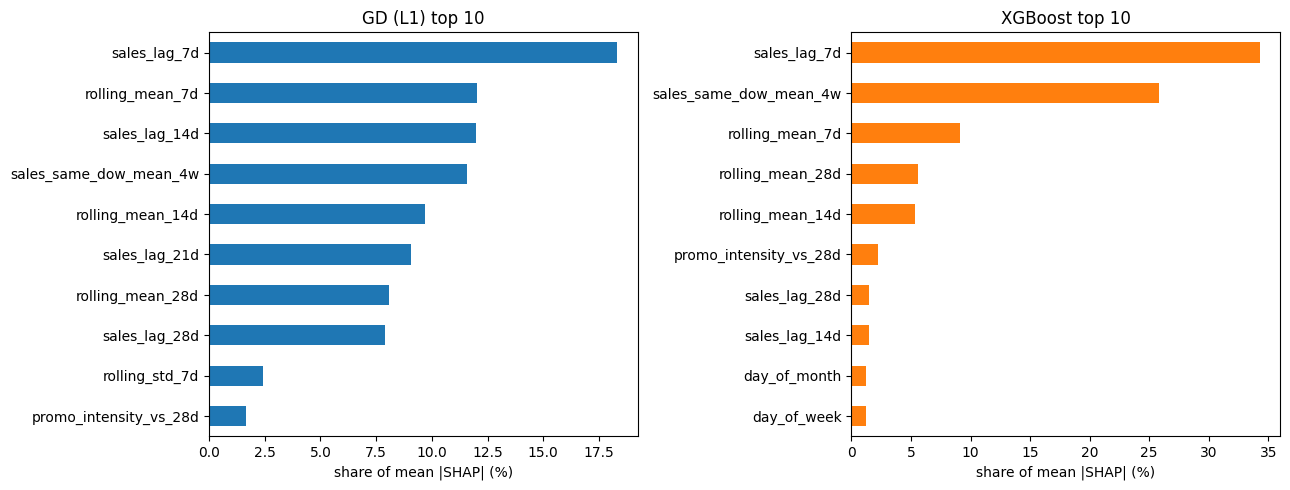

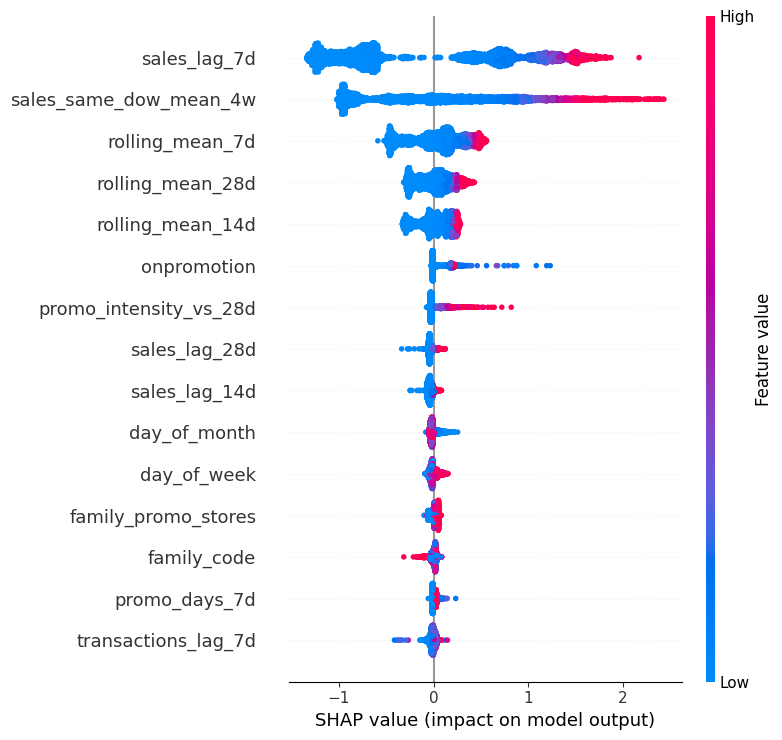

In [ ]:
import shap, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr

rng = np.random.RandomState(42)
idx = rng.choice(len(gd_valid), 5000, replace=False)
Xs_samp   = Xva_s[idx]
Xraw_samp = gd_valid.iloc[idx][features]

# 1) GD (linear model)
shap_gd = Xs_samp * gd_best.w

def base_name(c):
    if c in num_cols: return c
    for cat in cat_cols:
        if c.startswith(cat + "_"): return cat
    return c
groups = np.array([base_name(c) for c in gd_features])
shap_gd_grouped = pd.DataFrame(shap_gd, columns=gd_features).T.groupby(groups).sum().T
gd_imp = shap_gd_grouped.abs().mean()

# 2) XGBoost SHAP
expl = shap.TreeExplainer(final)
shap_xgb = expl.shap_values(Xraw_samp)
xgb_imp = pd.Series(np.abs(shap_xgb).mean(0), index=features)

# 3) Common features par comparison (% share)
common = gd_imp.index.intersection(xgb_imp.index)
cmp = pd.DataFrame({"GD_%":  100*gd_imp[common]/gd_imp[common].sum(),
                    "XGB_%": 100*xgb_imp[common]/xgb_imp[common].sum()})
cmp["GD_rank"]  = cmp["GD_%"].rank(ascending=False)
cmp["XGB_rank"] = cmp["XGB_%"].rank(ascending=False)
print(cmp.sort_values("XGB_%", ascending=False).head(15).round(2))

rho, p = spearmanr(cmp["GD_%"], cmp["XGB_%"])
print(f"\nSpearman rank correlation = {rho:.3f} (p={p:.4f})")
top_both = set(cmp.nlargest(10,"GD_%").index) & set(cmp.nlargest(10,"XGB_%").index)
print("Top-10 mein common features:", top_both)

# 4) Side-by-side bar chart
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
cmp["GD_%"].nlargest(10)[::-1].plot.barh(ax=ax[0], color="tab:blue",   title="GD (L1) top 10")
cmp["XGB_%"].nlargest(10)[::-1].plot.barh(ax=ax[1], color="tab:orange", title="XGBoost top 10")
for a in ax: a.set_xlabel("share of mean |SHAP| (%)")
plt.tight_layout(); plt.savefig("outputs/figures/shap_comparison.png", dpi=150); plt.show()

# 5) XGBoost beeswarm
shap.summary_plot(shap_xgb, Xraw_samp, max_display=15, show=False)
plt.savefig("outputs/figures/shap_xgb_summary.png", dpi=150, bbox_inches="tight"); plt.show()